# GA1-220501094-01-AA1-EV09 – Proyecto final: informe analítico
## Zona Fit Evolution: análisis de deserción de miembros

**Aprendiz:** Juan Diego Mejía Llano  
**Programa:** Análisis y Desarrollo de Software (ADSO) – SENA Regional Antioquia, ficha 3223873  
**Fecha:** noviembre de 2026

Este notebook hace el análisis descriptivo y visual de las tablas preparadas en la EV07 para responder la pregunta analítica del proyecto. Todas las cifras del informe [`reports/analytical_report.md`](../reports/analytical_report.md) salen de las salidas de este notebook. El uso de inteligencia artificial está documentado en [`prompts.md`](../prompts.md).

**Contenido**

1. Planteamiento: pregunta analítica y subpreguntas (Momento 2)
2. Diccionario de datos (Momento 2)
3. Carga y validación de los datos (Momento 3)
4. Análisis univariado (Momento 4)
5. Análisis bivariado y por segmentos (Momento 5)
6. Hallazgos, respuesta a la pregunta y recomendaciones (Momento 6)

# 1. Planteamiento (Momento 2)

**Problema:** Zona Fit Evolution necesita saber qué hace que un miembro deje de renovar su membresía, para actuar a tiempo con los miembros en riesgo.

**Pregunta analítica:** ¿Qué factores (tipo de plan, frecuencia de asistencia, horario de entrenamiento y antigüedad) influyen en que un miembro de Zona Fit Evolution cancele o no renueve su membresía durante sus primeros seis meses?

**Tipo de análisis:** descriptivo, con un componente diagnóstico (asociación entre factores y deserción).

**Cómo se mide la deserción**

- **Por membresía (`no_renovo`):** una membresía no se renueva si fue cancelada o si pasaron más de 30 días desde su fin sin una nueva compra. Solo se usan las membresías `observable == True`, cuyo resultado ya se conoce al corte (15/10/2026).
- **Por miembro (`desertor_6m`):** el miembro deja de renovar dentro de sus primeros 180 días. Solo se usan los miembros `evaluable == True`, cuya fecha de alta tiene al menos 180 + 30 días al corte.

**Subpreguntas**

| # | Subpregunta | Datos | Operación | Gráfica |
|---|---|---|---|---|
| 1 | ¿Cómo varía la deserción según el plan? | `nombre_plan`, `tipo_plan`, `no_renovo` · `tipo_plan_inicial`, `desertor_6m` | `groupby` + `agg` | Barras |
| 2 | ¿Qué relación hay entre la frecuencia semanal de asistencia y la deserción? | `visitas_semana`, `frecuencia`, `no_renovo` · `frecuencia_inicial`, `desertor_6m` | `groupby`, boxplot | Barras ordenadas y boxplot |
| 3 | ¿La franja horaria se asocia con la deserción? | `franja_principal`, `no_renovo` · `franja_inicial`, `desertor_6m` | `crosstab` normalizado | Barras agrupadas |
| 4 | ¿Cómo cambia el riesgo según la antigüedad y cuántos miembros desertan en sus primeros 6 meses? | `tramo_antiguedad`, `antiguedad_dias`, `no_renovo` · `desertor_6m` | `groupby`, correlación | Barras y dispersión |
| 5 | ¿Cómo evoluciona la tasa de no renovación según el mes de inicio de la membresía? | `fecha_inicio`, `no_renovo` (solo observables) | `groupby` por mes | Líneas |

Las subpreguntas se validaron contra las columnas reales (apartado 1 de la bitácora): `tipo_plan` solo tiene dos valores, así que el detalle se hace con `nombre_plan`; las membresías sin visitas no tienen franja y se excluyen en la subpregunta 3; y los últimos meses de la serie tienen pocas membresías observables (censura al corte).

# 2. Diccionario de datos (Momento 2)

Tablas generadas en la EV07 (`data/processed/`). Los tipos estadísticos siguen la clasificación de la EV08.

### `zonafit_memberships_analytic` (una fila por membresía)

| variable | descripción | tipo en Pandas | tipo estadístico | unidad |
|---|---|---|---|---|
| id_membresia | Identificador de la membresía | int16 | Cualitativa nominal | — |
| id_miembro | Identificador del miembro que compró la membresía | int16 | Cualitativa nominal | — |
| id_plan | Identificador del plan comprado | int8 | Cualitativa nominal | — |
| fecha_inicio | Primer día de vigencia de la membresía | datetime64[us] | Cuantitativa continua | fecha |
| fecha_fin | Último día de vigencia de la membresía | datetime64[us] | Cuantitativa continua | fecha |
| precio_pagado | Valor cobrado por la membresía (puede tener descuento) | int64 | Cuantitativa continua | COP |
| estado | Estado al corte: Activa, Vencida o Cancelada | category | Cualitativa nominal | — |
| siguiente_inicio | Inicio de la siguiente membresía del mismo miembro (vacía si no hay) | datetime64[us] | Cuantitativa continua | fecha |
| dias_hasta_siguiente | Días entre el fin de esta membresía y el inicio de la siguiente | float64 | Cuantitativa discreta | días |
| renovada | True si compró otra membresía en los 30 días siguientes al fin y no la canceló | bool | Cualitativa nominal | — |
| observable | True si ya se conoce el resultado de renovación al corte | bool | Cualitativa nominal | — |
| no_renovo | True si la membresía es observable y no se renovó | bool | Cualitativa nominal | — |
| numero_membresia | Orden de la membresía en el historial del miembro (1 = primera) | int64 | Cuantitativa discreta | membresías |
| antiguedad_dias | Días desde la primera membresía del miembro hasta el inicio de esta | int64 | Cuantitativa discreta | días |
| nombre_plan | Nombre comercial del plan | str | Cualitativa nominal | — |
| tipo_plan | Ilimitado o Tiquetera | category | Cualitativa nominal | — |
| duracion_dias | Días de vigencia del plan | int16 | Cuantitativa discreta | días |
| precio | Precio de lista del plan | int32 | Cuantitativa continua | COP |
| genero | Género del miembro (M, F o Sin dato) | category | Cualitativa nominal | — |
| fecha_nacimiento | Fecha de nacimiento del miembro | datetime64[us] | Cuantitativa continua | fecha |
| comuna | Comuna de Medellín donde vive el miembro (o Sin dato) | category | Cualitativa nominal | — |
| canal_captacion | Instagram, Referido, Walk-in, Volante o Convenio empresarial | category | Cualitativa nominal | — |
| fecha_registro | Fecha de inscripción del miembro | datetime64[us] | Cuantitativa continua | fecha |
| pagado_aprobado | Suma de pagos aprobados de la membresía | int64 | Cuantitativa continua | COP |
| pagado_pendiente | Suma de pagos pendientes de la membresía | int64 | Cuantitativa continua | COP |
| pagado_rechazado | Suma de pagos rechazados de la membresía | int64 | Cuantitativa continua | COP |
| numero_pagos | Cantidad de pagos registrados para la membresía | int64 | Cuantitativa discreta | pagos |
| visitas_mañana | Ingresos válidos entre las 5:00 y las 11:59 | int16 | Cuantitativa discreta | visitas |
| visitas_tarde | Ingresos válidos entre las 12:00 y las 17:59 | int16 | Cuantitativa discreta | visitas |
| visitas_noche | Ingresos válidos entre las 18:00 y las 21:59 | int16 | Cuantitativa discreta | visitas |
| visitas | Total de ingresos válidos durante la membresía | int16 | Cuantitativa discreta | visitas |
| primera_visita | Fecha y hora del primer ingreso de la membresía | datetime64[us] | Cuantitativa continua | fecha y hora |
| ultima_visita | Fecha y hora del último ingreso de la membresía | datetime64[us] | Cuantitativa continua | fecha y hora |
| visitas_semana | Promedio de visitas por semana durante la vigencia (hasta el corte) | float64 | Cuantitativa continua | visitas/semana |
| frecuencia | Rango de visitas semanales (hasta 1, más de 1 a 2, más de 2 a 3, más de 3) | category | Cualitativa ordinal | — |
| franja_principal | Franja con más ingresos: mañana, tarde o noche (vacía si no hubo visitas) | str | Cualitativa ordinal | — |
| tramo_antiguedad | 0 a 6 meses, 6 a 12 meses, más de 12 meses | category | Cualitativa ordinal | — |
| edad_al_inicio | Edad en años cumplidos al iniciar la membresía | Int16 | Cuantitativa discreta | años |
| pago_completo | True si los pagos aprobados cubren el precio pagado | bool | Cualitativa nominal | — |

### `zonafit_members_analytic` (una fila por miembro)

| variable | descripción | tipo en Pandas | tipo estadístico | unidad |
|---|---|---|---|---|
| id_miembro | Identificador del miembro | int16 | Cualitativa nominal | — |
| documento_hash | Documento de identidad anonimizado | str | Cualitativa nominal | — |
| genero | Género registrado (M, F o Sin dato) | category | Cualitativa nominal | — |
| fecha_nacimiento | Fecha de nacimiento | datetime64[us] | Cuantitativa continua | fecha |
| comuna | Comuna de Medellín donde vive (o Sin dato) | category | Cualitativa nominal | — |
| canal_captacion | Canal por el que llegó al gimnasio | category | Cualitativa nominal | — |
| fecha_registro | Fecha de inscripción | datetime64[us] | Cuantitativa continua | fecha |
| membresias | Número de membresías compradas | int64 | Cuantitativa discreta | membresías |
| ultima_fecha_fin | Fecha de fin de su membresía más reciente | datetime64[us] | Cuantitativa continua | fecha |
| membresias_no_renovadas | Número de membresías que no renovó | int64 | Cuantitativa discreta | membresías |
| visitas_totales | Total de ingresos válidos en todo su historial | int16 | Cuantitativa discreta | visitas |
| total_pagado | Suma de lo pagado en todas sus membresías | int64 | Cuantitativa continua | COP |
| plan_inicial | Nombre del plan de su primera membresía | str | Cualitativa nominal | — |
| tipo_plan_inicial | Tipo del plan de su primera membresía | category | Cualitativa nominal | — |
| visitas_semana_inicial | Visitas promedio por semana en su primera membresía | float64 | Cuantitativa continua | visitas/semana |
| franja_inicial | Franja principal de su primera membresía | str | Cualitativa ordinal | — |
| fecha_alta | Fecha de inicio de su primera membresía | datetime64[us] | Cuantitativa continua | fecha |
| primera_no_renovacion | Fecha de su primera membresía no renovada (vacía si siempre renovó) | datetime64[us] | Cuantitativa continua | fecha |
| evaluable | True si ya pasaron 180 + 30 días desde el alta (se puede evaluar la deserción temprana) | bool | Cualitativa nominal | — |
| desertor_6m | True si dejó de renovar dentro de los primeros 180 días desde el alta | bool | Cualitativa nominal | — |
| frecuencia_inicial | Rango de visitas semanales en su primera membresía | category | Cualitativa ordinal | — |
| edad_al_alta | Edad en años cumplidos en la fecha de alta | Int16 | Cuantitativa discreta | años |
| activo_al_corte | True si su membresía más reciente sigue vigente al 15/10/2026 | bool | Cualitativa nominal | — |

**Clasificaciones discutibles**

- **Fechas:** el tiempo es continuo; en el análisis se agrupan por mes para la serie temporal.
- **Montos en COP:** son enteros porque el peso no usa centavos, pero el dinero se mide, no se cuenta: se tratan como continuos.
- **Edad y columnas en días:** se registran en unidades enteras (años cumplidos, días), por eso son discretas.
- **Franja:** mañana, tarde y noche siguen el orden del día; por eso es ordinal.
- **Booleanos e identificadores:** son nominales; un identificador numérico no admite operaciones aritméticas.

# 3. Carga y validación de los datos (Momento 3)

Se importan las librerías del análisis. Matplotlib se usa para las gráficas de los momentos 4 y 5.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

print(f"pandas {pd.__version__}")

pandas 3.0.5


Se cargan las dos tablas con rutas relativas al notebook y se valida que las dimensiones y los tipos coincidan con el diccionario de datos.

In [2]:
# Rutas relativas desde la carpeta notebooks/
RUTA_MEMBRESIAS = "../data/processed/zonafit_memberships_analytic.parquet"
RUTA_MIEMBROS = "../data/processed/zonafit_members_analytic.parquet"

# 1. Cargar las dos tablas analíticas (Parquet conserva los tipos de dato)
membresias = pd.read_parquet(RUTA_MEMBRESIAS)
miembros = pd.read_parquet(RUTA_MIEMBROS)

# 2. Validar dimensiones esperadas
assert membresias.shape == (3425, 39), f"membresias tiene {membresias.shape}, se esperaba (3425, 39)"
assert miembros.shape == (900, 23), f"miembros tiene {miembros.shape}, se esperaba (900, 23)"

# 3. Tipos esperados según el diccionario de datos
tipos_membresias = {
    "id_membresia": "int16", "id_miembro": "int16", "id_plan": "int8",
    "fecha_inicio": "datetime64[us]", "fecha_fin": "datetime64[us]", "precio_pagado": "int64",
    "estado": "category", "siguiente_inicio": "datetime64[us]", "dias_hasta_siguiente": "float64",
    "renovada": "bool", "observable": "bool", "no_renovo": "bool", "numero_membresia": "int64",
    "antiguedad_dias": "int64", "nombre_plan": "str", "tipo_plan": "category", "duracion_dias": "int16",
    "precio": "int32", "genero": "category", "fecha_nacimiento": "datetime64[us]", "comuna": "category",
    "canal_captacion": "category", "fecha_registro": "datetime64[us]", "pagado_aprobado": "int64",
    "pagado_pendiente": "int64", "pagado_rechazado": "int64", "numero_pagos": "int64",
    "visitas_mañana": "int16", "visitas_tarde": "int16", "visitas_noche": "int16", "visitas": "int16",
    "primera_visita": "datetime64[us]", "ultima_visita": "datetime64[us]", "visitas_semana": "float64",
    "frecuencia": "category", "franja_principal": "str", "tramo_antiguedad": "category",
    "edad_al_inicio": "Int16", "pago_completo": "bool",
}
tipos_miembros = {
    "id_miembro": "int16", "documento_hash": "str", "genero": "category",
    "fecha_nacimiento": "datetime64[us]", "comuna": "category", "canal_captacion": "category",
    "fecha_registro": "datetime64[us]", "membresias": "int64", "ultima_fecha_fin": "datetime64[us]",
    "membresias_no_renovadas": "int64", "visitas_totales": "int16", "total_pagado": "int64",
    "plan_inicial": "str", "tipo_plan_inicial": "category", "visitas_semana_inicial": "float64",
    "franja_inicial": "str", "fecha_alta": "datetime64[us]", "primera_no_renovacion": "datetime64[us]",
    "evaluable": "bool", "desertor_6m": "bool", "frecuencia_inicial": "category",
    "edad_al_alta": "Int16", "activo_al_corte": "bool",
}

# Comparar tipo esperado vs. tipo real (sin bucles: se alinean dos Series por nombre de columna)
def comparar_tipos(df, esperados):
    comparacion = pd.DataFrame({
        "esperado": pd.Series(esperados),
        "real": df.dtypes.astype(str),
    })
    return comparacion[comparacion["esperado"] != comparacion["real"]]

diferencias_membresias = comparar_tipos(membresias, tipos_membresias)
diferencias_miembros = comparar_tipos(miembros, tipos_miembros)

print("Columnas de membresias que no coinciden con el diccionario:")
print(diferencias_membresias if not diferencias_membresias.empty else "Ninguna")
print("\nColumnas de miembros que no coinciden con el diccionario:")
print(diferencias_miembros if not diferencias_miembros.empty else "Ninguna")

assert diferencias_membresias.empty, "Los tipos de membresias no coinciden con el diccionario"
assert diferencias_miembros.empty, "Los tipos de miembros no coinciden con el diccionario"

# 4. Resumen de cada tabla
print("\n--- membresias ---")
membresias.info()
print("\n--- miembros ---")
miembros.info()


Columnas de membresias que no coinciden con el diccionario:
Ninguna

Columnas de miembros que no coinciden con el diccionario:
Ninguna

--- membresias ---
<class 'pandas.DataFrame'>
RangeIndex: 3425 entries, 0 to 3424
Data columns (total 39 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   id_membresia          3425 non-null   int16         
 1   id_miembro            3425 non-null   int16         
 2   id_plan               3425 non-null   int8          
 3   fecha_inicio          3425 non-null   datetime64[us]
 4   fecha_fin             3425 non-null   datetime64[us]
 5   precio_pagado         3425 non-null   int64         
 6   estado                3425 non-null   category      
 7   siguiente_inicio      2525 non-null   datetime64[us]
 8   dias_hasta_siguiente  2525 non-null   float64       
 9   renovada              3425 non-null   bool          
 10  observable            3425 non-null   bool      

**Interpretación:** las dos tablas cargan con las dimensiones esperadas (3.425 membresías y 900 miembros) y sus 62 columnas tienen exactamente los tipos del diccionario. Gracias al formato Parquet, las fechas llegan como `datetime64`, las categorías como `category` y la edad como entero con nulos (`Int16`), sin conversiones adicionales.

Los faltantes que muestra `info()` son esperados: `siguiente_inicio` y `dias_hasta_siguiente` están vacíos cuando no hubo una membresía posterior, `primera_visita`, `ultima_visita` y `franja_principal` cuando no hubo visitas, la edad cuando falta la fecha de nacimiento y `primera_no_renovacion` cuando el miembro siempre renovó.

## Verificación de calidad

Antes de analizar se comprueba que los problemas del diagnóstico (EV06) quedaron resueltos en la EV07 y que se cumplen las reglas del análisis.

In [3]:
FECHA_CORTE = pd.Timestamp("2026-10-15")

# 1. Estado: ninguna membresía puede seguir "Activa" si su fecha de fin ya pasó
activas_vencidas = membresias[(membresias["estado"] == "Activa") & (membresias["fecha_fin"] < FECHA_CORTE)]
assert activas_vencidas.empty, f"Hay {len(activas_vencidas)} membresías Activa ya vencidas"

# 2. Duplicados: identificadores únicos y ninguna persona inscrita dos veces
assert membresias["id_membresia"].is_unique, "Hay membresías duplicadas"
assert miembros["id_miembro"].is_unique, "Hay miembros duplicados (id_miembro)"
assert miembros["documento_hash"].is_unique, "Hay personas inscritas dos veces (documento_hash)"
# Pagos duplicados: si se repitiera un pago, lo aprobado superaría el valor cobrado
assert (membresias["pagado_aprobado"] <= membresias["precio_pagado"]).all(), "Pagos aprobados mayores al precio: posibles pagos duplicados"

# 3. Tipos de dato: fechas como datetime y montos como números
fechas_m = membresias[["fecha_inicio", "fecha_fin", "fecha_registro", "fecha_nacimiento"]]
fechas_s = miembros[["fecha_registro", "fecha_nacimiento", "fecha_alta", "ultima_fecha_fin"]]
assert fechas_m.dtypes.map(pd.api.types.is_datetime64_any_dtype).all(), "Hay fechas como texto en membresías"
assert fechas_s.dtypes.map(pd.api.types.is_datetime64_any_dtype).all(), "Hay fechas como texto en miembros"
montos = membresias[["precio_pagado", "precio", "pagado_aprobado", "pagado_pendiente", "pagado_rechazado"]]
assert montos.dtypes.map(pd.api.types.is_numeric_dtype).all(), "Hay montos como texto en membresías"
assert pd.api.types.is_numeric_dtype(miembros["total_pagado"]), "total_pagado no es numérico"

# 4. Categorías y faltantes de genero y comuna
assert set(miembros["genero"].unique()) <= {"M", "F", "Sin dato"}, "genero tiene categorías sin unificar"
assert set(membresias["genero"].unique()) <= {"M", "F", "Sin dato"}, "genero (membresías) tiene categorías sin unificar"
assert miembros[["genero", "comuna"]].notna().all().all(), "Hay faltantes sin tratar en genero o comuna (miembros)"
assert membresias[["genero", "comuna"]].notna().all().all(), "Hay faltantes sin tratar en genero o comuna (membresías)"

# 5. Reglas de negocio del análisis
assert not (membresias["no_renovo"] & ~membresias["observable"]).any(), "no_renovo es True en membresías no observables"
no_evaluables = miembros[~miembros["evaluable"]]
assert (no_evaluables["fecha_alta"] > FECHA_CORTE - pd.Timedelta(days=210)).all(), "Hay miembros no evaluables con más de 210 días desde el alta"
assert (membresias["visitas_semana"] >= 0).all(), "visitas_semana tiene valores negativos"
suma_franjas = membresias[["visitas_mañana", "visitas_tarde", "visitas_noche"]].sum(axis=1)
assert (suma_franjas == membresias["visitas"]).all(), "visitas no coincide con la suma de las tres franjas"

print("Calidad verificada: todas las reglas se cumplen.")
print(f"Miembros evaluables a 6 meses: {miembros['evaluable'].sum()}")


Calidad verificada: todas las reglas se cumplen.
Miembros evaluables a 6 meses: 671


**Interpretación:** los problemas del diagnóstico ya no aparecen. No hay membresías `Activa` vencidas, ni duplicados, ni fechas o montos como texto, y `genero` y `comuna` no tienen faltantes sin tratar. Se cumplen además las reglas del análisis.

De los 900 miembros, **671 son evaluables** a seis meses. La regla de `evaluable` es necesaria: los miembros que se inscribieron hace poco y ya desertaron también aparecen con `desertor_6m = True`, así que incluirlos inflaría la tasa de deserción temprana.

# 4. Análisis univariado (Momento 4)

Se describe cada variable relevante por separado: las cuantitativas con medidas de tendencia central y de dispersión, y las cualitativas con frecuencias absolutas y relativas. Se usan todas las membresías, salvo en la variable objetivo, que lleva su filtro.

## 4.1 Variables cuantitativas

In [4]:
# Paso 1. Medidas de tendencia central y dispersión de las variables cuantitativas
# Se convierten a float64 para que la edad (Int16 con nulos) se calcule igual que las demás
cuantitativas = membresias[["visitas_semana", "antiguedad_dias", "edad_al_inicio", "precio_pagado"]].astype("float64")

resumen = cuantitativas.agg(["mean", "median", "std", "min", "max"]).T
resumen["rango"] = resumen["max"] - resumen["min"]
resumen["Q1"] = cuantitativas.quantile(0.25)
resumen["Q3"] = cuantitativas.quantile(0.75)
resumen["IQR"] = resumen["Q3"] - resumen["Q1"]
resumen["n"] = cuantitativas.count()   # datos no nulos usados en cada cálculo

resumen = resumen.rename(columns={"mean": "media", "median": "mediana", "std": "desv_estandar",
                                  "min": "mínimo", "max": "máximo"})
resumen.round(2)


,media,mediana,desv_estandar,mínimo,máximo,rango,Q1,Q3,IQR,n
visitas_semana,2.62,2.8,1.18,0.0,7.0,7.0,1.63,3.5,1.87,3425
antiguedad_dias,123.14,90.0,133.31,0.0,634.0,634.0,0.00,189.0,189.00,3425
edad_al_inicio,28.75,28.0,8.93,15.0,58.0,43.0,22.00,35.0,13.00,3245
precio_pagado,118108.03,90000.0,123724.85,54000.0,840000.0,786000.0,70000.00,90000.0,20000.00,3425


**Interpretación:**

- **`visitas_semana`:** la mitad de las membresías tiene 2,8 visitas por semana o menos (media 2,62), y el 50 % central está entre 1,63 y 3,5. La media y la mediana están cerca, así que la distribución es bastante simétrica. Es el factor *frecuencia* de la pregunta.
- **`antiguedad_dias`:** la mediana es de 90 días y Q1 es 0, porque al menos una de cada cuatro membresías es la primera del miembro. La media (123 días) supera a la mediana: hay pocos miembros con mucha antigüedad (hasta 634 días). Esto confirma que el negocio depende mucho de miembros nuevos, justo el grupo de la pregunta.
- **`edad_al_inicio`:** media de 28,75 años (mediana 28; entre 15 y 58). Se calcula con 3.245 datos porque faltan fechas de nacimiento.
- **`precio_pagado`:** la mediana es de 90.000 COP y el 50 % central paga entre 70.000 y 90.000 (IQR de 20.000), pero la media sube a 118.108 COP por los planes largos (hasta 840.000). Es una distribución sesgada a la derecha: la mediana representa mejor el precio típico.

## 4.2 Variables cualitativas

In [5]:
# Paso 2. Frecuencias absolutas y relativas de las variables cualitativas
def tabla_frecuencias(serie, orden=None):
    """Frecuencia absoluta y relativa (%) en una sola tabla, con los nulos incluidos.
    Si se da un orden (variables ordinales), las filas se muestran en ese orden."""
    tabla = pd.DataFrame({
        "frecuencia": serie.value_counts(dropna=False),
        "porcentaje": serie.value_counts(dropna=False, normalize=True) * 100,
    })
    if orden is not None:
        tabla = tabla.reindex(orden)
    return tabla.rename_axis(serie.name).round(2)

# Nominal: de mayor a menor frecuencia
frec_plan = tabla_frecuencias(membresias["nombre_plan"])
# Ordinales: en el orden lógico de sus categorías
frec_frecuencia = tabla_frecuencias(membresias["frecuencia"], orden=membresias["frecuencia"].cat.categories)
frec_tramo = tabla_frecuencias(membresias["tramo_antiguedad"], orden=membresias["tramo_antiguedad"].cat.categories)
# franja_principal es texto: el orden se da a mano y se agrega el nulo (membresías sin visitas)
frec_franja = tabla_frecuencias(membresias["franja_principal"], orden=["mañana", "tarde", "noche", None])

display(frec_plan, frec_frecuencia, frec_tramo, frec_franja)


,frecuencia,porcentaje
nombre_plan,,
Mensual ilimitado,1387,40.50
Mensual estudiante,1177,34.36
Tiquetera 12 ingresos,369,10.77
Trimestral ilimitado,314,9.17
Semestral ilimitado,120,3.50
Anual ilimitado,58,1.69


,frecuencia,porcentaje
frecuencia,,
hasta 1,407,11.88
más de 1 a 2,633,18.48
más de 2 a 3,1003,29.28
más de 3,1382,40.35


,frecuencia,porcentaje
tramo_antiguedad,,
0 a 6 meses,2423,70.74
6 a 12 meses,745,21.75
más de 12 meses,257,7.50


,frecuencia,porcentaje
franja_principal,,
mañana,1802,52.61
tarde,1000,29.20
noche,609,17.78
NaN,14,0.41


**Interpretación:**

- **Plan:** los planes mensuales concentran el 74,86 % de las membresías (Mensual ilimitado 40,50 % y Mensual estudiante 34,36 %); la tiquetera suma el 10,77 %, y los planes semestral y anual son poco frecuentes (3,50 % y 1,69 %). Sus tasas posteriores se basan en pocos casos.
- **Frecuencia:** el 40,35 % de las membresías supera las 3 visitas semanales, mientras que el 11,88 % tiene 1 visita o menos. Ese grupo es el de mayor riesgo que se analizará en el Momento 5.
- **Antigüedad:** el 70,74 % de las membresías ocurre en los primeros 6 meses del miembro, lo que refuerza que la retención temprana es el punto crítico.
- **Franja:** la mañana es la franja principal del 52,61 % de las membresías, seguida de la tarde (29,20 %) y la noche (17,78 %). Hay 14 membresías (0,41 %) sin franja porque no registraron visitas.

## 4.3 Variable objetivo

In [6]:
# Paso 3. Proporción de la variable objetivo, cada una con su filtro
observables = membresias[membresias["observable"]]
evaluables = miembros[miembros["evaluable"]]

frec_no_renovo = tabla_frecuencias(observables["no_renovo"])
frec_desertor = tabla_frecuencias(evaluables["desertor_6m"])

print(f"Membresías observables: {len(observables)} de {len(membresias)}")
print(f"Tasa de no renovación: {observables['no_renovo'].mean():.2%}")
print(f"Miembros evaluables: {len(evaluables)} de {len(miembros)}")
print(f"Tasa de deserción en los primeros 6 meses: {evaluables['desertor_6m'].mean():.2%}")
display(frec_no_renovo, frec_desertor)


Membresías observables: 3084 de 3425
Tasa de no renovación: 21.27%
Miembros evaluables: 671 de 900
Tasa de deserción en los primeros 6 meses: 61.10%


,frecuencia,porcentaje
no_renovo,,
False,2428,78.73
True,656,21.27


,frecuencia,porcentaje
desertor_6m,,
True,410,61.1
False,261,38.9


**Interpretación:** de 3.084 membresías observables, el 21,27 % no se renovó. Medida por miembro, la deserción es mucho mayor: de 671 miembros evaluables, el 61,10 % dejó de renovar en algún momento de sus primeros seis meses. Es decir, la mayoría de los miembros nuevos abandona pronto aunque cada membresía, vista por separado, se renueve casi 4 de cada 5 veces. Esta diferencia justifica medir cada factor también por miembro.

## 4.4 Visualización univariada

Cada variable se representa con la gráfica que corresponde a su tipo, según la tabla de la EV08: histograma para la cuantitativa continua, barras para la nominal y las ordinales (estas en su orden lógico) y boxplot para el precio, que está sesgado. Las figuras se guardan en `reports/figures/`.

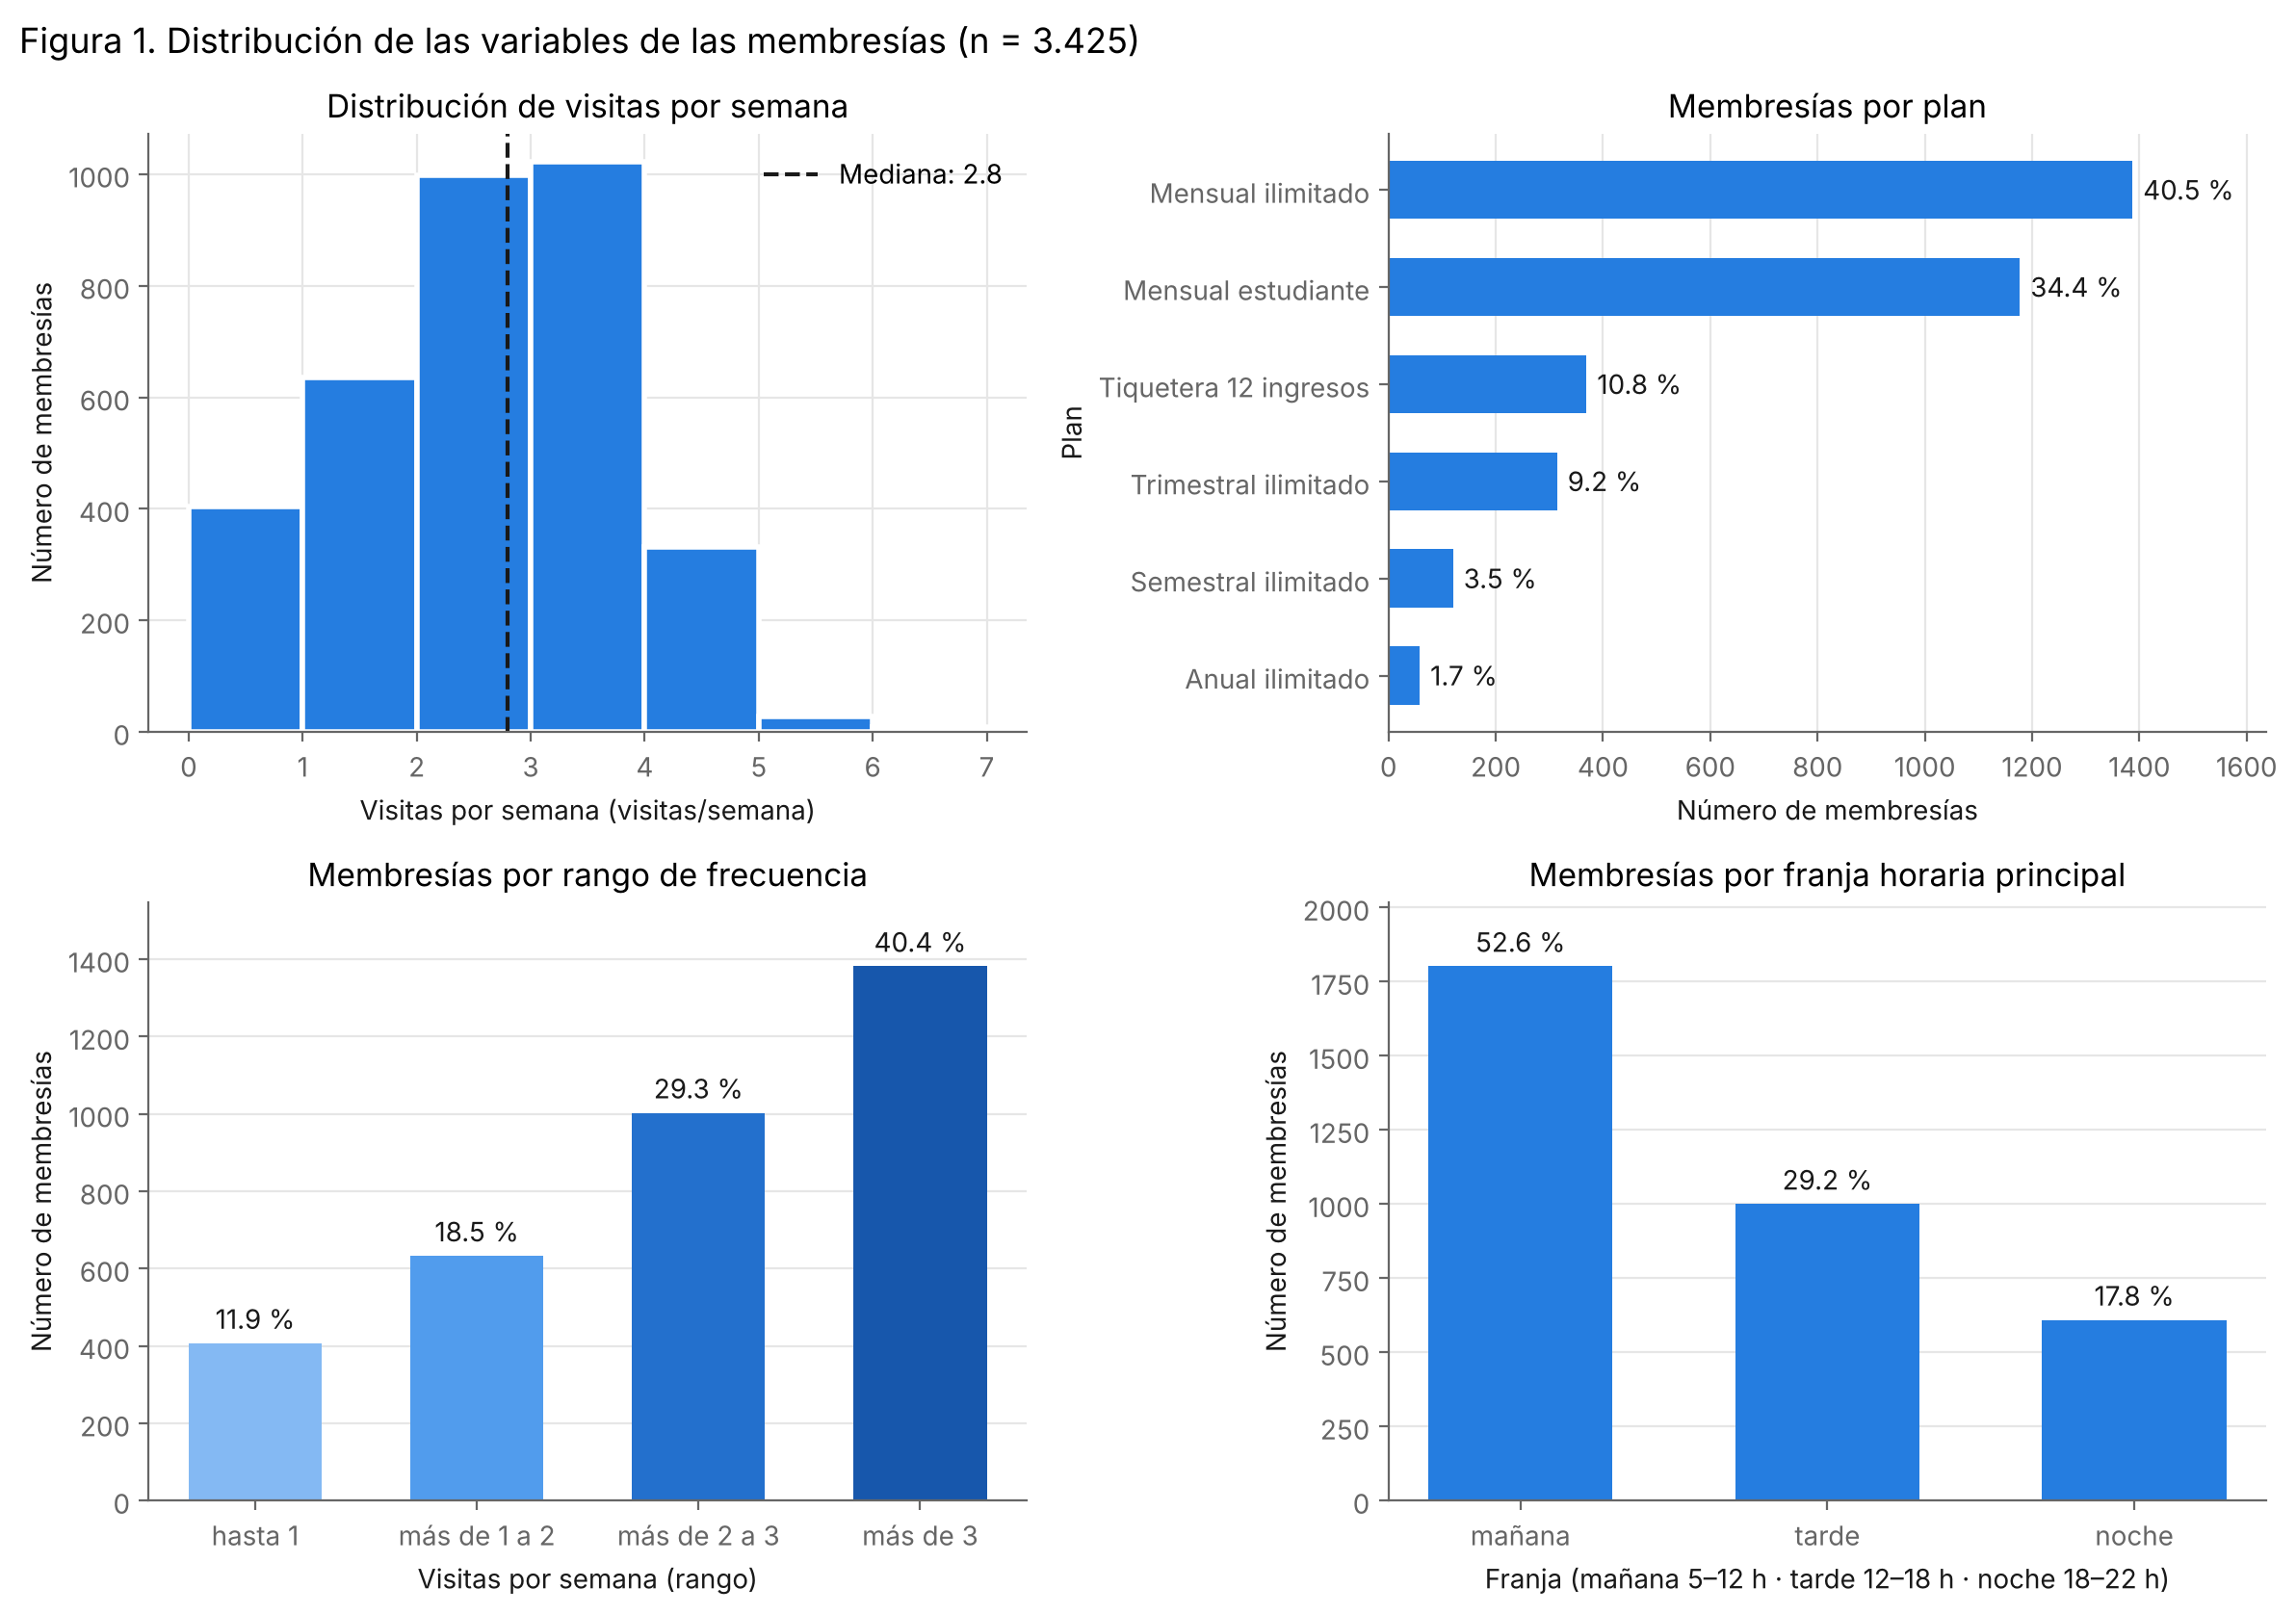

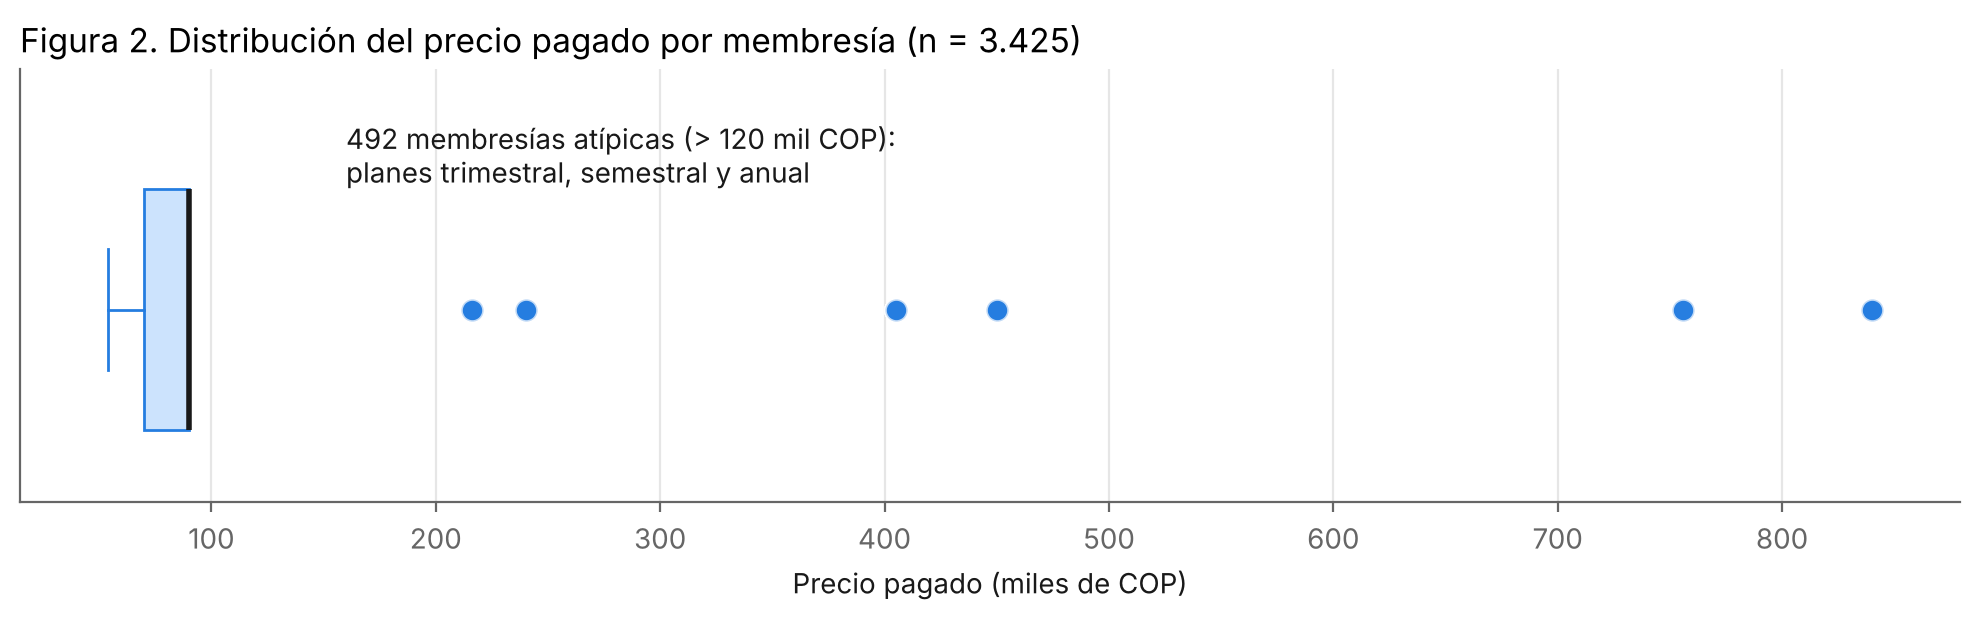

In [7]:
from pathlib import Path

# Carpeta de figuras (se crea si no existe)
RUTA_FIGURAS = Path("../reports/figures")
RUTA_FIGURAS.mkdir(parents=True, exist_ok=True)

# Estilo sobrio: un solo color por serie, ejes y cuadrícula discretos
AZUL = "#257de0"
AZUL_ORDINAL = ["#84b9f3", "#519ced", "#2370cd", "#1757ac"]   # claro → oscuro = menos → más visitas
plt.rcParams.update({
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#666666", "axes.labelcolor": "#191919",
    "xtick.color": "#666666", "ytick.color": "#666666",
    "axes.grid": True, "grid.color": "#e6e6e6", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "font.size": 10,
})

fig, ejes = plt.subplots(2, 2, figsize=(12, 8.5))

# 1) visitas_semana (cuantitativa continua) → histograma
ax = ejes[0, 0]
ax.hist(membresias["visitas_semana"], bins=range(0, 8), color=AZUL, edgecolor="white", linewidth=2)
ax.axvline(membresias["visitas_semana"].median(), color="#191919", linestyle="--", linewidth=1.5,
           label=f"Mediana: {membresias['visitas_semana'].median():.1f}")
ax.set_title("Distribución de visitas por semana")
ax.set_xlabel("Visitas por semana (visitas/semana)")
ax.set_ylabel("Número de membresías")
ax.legend(frameon=False)

# 2) nombre_plan (cualitativa nominal) → barras horizontales ordenadas
ax = ejes[0, 1]
planes = frec_plan.sort_values("frecuencia")
ax.barh(planes.index, planes["frecuencia"], color=AZUL, height=0.6)
ax.bar_label(ax.containers[0], labels=planes["porcentaje"].map("{:.1f} %".format), padding=4, color="#191919")
ax.set_title("Membresías por plan")
ax.set_xlabel("Número de membresías")
ax.set_ylabel("Plan")
ax.set_xlim(0, planes["frecuencia"].max() * 1.18)
ax.grid(axis="y", visible=False)

# 3) frecuencia (cualitativa ordinal) → barras en orden lógico
ax = ejes[1, 0]
ax.bar(frec_frecuencia.index.astype(str), frec_frecuencia["frecuencia"], color=AZUL_ORDINAL, width=0.6)
ax.bar_label(ax.containers[0], labels=frec_frecuencia["porcentaje"].map("{:.1f} %".format), padding=3, color="#191919")
ax.set_title("Membresías por rango de frecuencia")
ax.set_xlabel("Visitas por semana (rango)")
ax.set_ylim(0, frec_frecuencia["frecuencia"].max() * 1.12)
ax.set_ylabel("Número de membresías")
ax.grid(axis="x", visible=False)

# 4) franja_principal (cualitativa ordinal) → barras en orden del día (sin las 14 membresías sin visitas)
ax = ejes[1, 1]
franjas = frec_franja.loc[["mañana", "tarde", "noche"]]
ax.bar(franjas.index, franjas["frecuencia"], color=AZUL, width=0.6)
ax.bar_label(ax.containers[0], labels=franjas["porcentaje"].map("{:.1f} %".format), padding=3, color="#191919")
ax.set_title("Membresías por franja horaria principal")
ax.set_xlabel("Franja (mañana 5–12 h · tarde 12–18 h · noche 18–22 h)")
ax.set_ylim(0, franjas["frecuencia"].max() * 1.12)
ax.set_ylabel("Número de membresías")
ax.grid(axis="x", visible=False)

fig.suptitle("Figura 1. Distribución de las variables de las membresías (n = 3.425)", fontsize=13, x=0.01, ha="left")
fig.tight_layout()
fig.savefig(RUTA_FIGURAS / "univariate_distributions.png", dpi=150, bbox_inches="tight")
plt.show()

# 5) precio_pagado (cuantitativa continua, sesgada) → boxplot horizontal
# Límite de atípicos de la regla de Tukey: Q3 + 1,5 × IQR
q1, q3 = membresias["precio_pagado"].quantile([0.25, 0.75])
limite = q3 + 1.5 * (q3 - q1)
atipicos = membresias[membresias["precio_pagado"] > limite]

fig, ax = plt.subplots(figsize=(10, 3.2))
ax.boxplot(membresias["precio_pagado"] / 1000, orientation="horizontal", widths=0.5, patch_artist=True,
           boxprops={"facecolor": "#cce3fd", "edgecolor": AZUL}, medianprops={"color": "#191919", "linewidth": 2},
           whiskerprops={"color": AZUL}, capprops={"color": AZUL},
           flierprops={"marker": "o", "markersize": 8, "markerfacecolor": AZUL, "markeredgecolor": "white", "alpha": 0.6})
ax.set_title("Figura 2. Distribución del precio pagado por membresía (n = 3.425)", loc="left")
ax.set_xlabel("Precio pagado (miles de COP)")
ax.set_yticks([])
# Cada punto representa muchas membresías con el mismo precio: se indica cuántas son y de qué planes
ax.annotate(f"{len(atipicos)} membresías atípicas (> {limite / 1000:.0f} mil COP):\n"
            "planes trimestral, semestral y anual",
            xy=(limite / 1000, 1.28), xytext=(limite / 1000 + 40, 1.32), color="#191919", va="center")
ax.set_ylim(0.6, 1.5)
ax.grid(axis="y", visible=False)
fig.tight_layout()
fig.savefig(RUTA_FIGURAS / "price_paid_boxplot.png", dpi=150, bbox_inches="tight")
plt.show()


**Interpretación:**

- **Figura 1 – visitas por semana:** la mayoría de las membresías está entre 2 y 4 visitas semanales (mediana 2,8). Hay un grupo de unas 400 membresías con menos de 1 visita por semana, que es el extremo de bajo uso.
- **Figura 1 – plan:** las barras confirman el peso de los planes mensuales (40,5 % + 34,4 %). Los planes largos son minoritarios, así que sus tasas de deserción se basan en pocos casos.
- **Figura 1 – frecuencia:** el grupo más grande es el de más de 3 visitas (40,4 %), y el de 1 visita o menos es el más pequeño (11,9 %).
- **Figura 1 – franja:** la mañana domina (52,6 %), lo que indica cuándo se concentra la operación del gimnasio.
- **Figura 2 – precio pagado:** la caja es muy estrecha (de 70 a 90 mil COP) y la mediana coincide con Q3 (90 mil COP), porque la mayoría compra planes mensuales. Los 492 valores por encima de 120 mil COP no son errores: son membresías trimestrales, semestrales y anuales. Por eso el precio se analiza por plan y no como una sola distribución.

# 5. Análisis bivariado y por segmentos (Momento 5)

Se responde cada subpregunta cruzando el factor con la deserción, medida de dos formas:

- **Tasa de no renovación:** porcentaje de membresías observables que no se renovaron.
- **Tasa de deserción a 6 meses:** porcentaje de miembros evaluables que dejaron de renovar en sus primeros 180 días, según el factor de su **primera** membresía (plan, frecuencia y franja iniciales).

La función `desercion_por_factor` calcula las dos tasas para un mismo factor y las une en una sola tabla con `join`.

In [8]:
# Función reutilizable: compara la deserción por membresía y por miembro para un mismo factor
def desercion_por_factor(col_membresia, col_miembro, nombre_factor):
    """Une en una tabla la tasa de no renovación (membresías observables)
    y la tasa de deserción a 6 meses (miembros evaluables) de un factor."""
    por_membresia = (observables
        .groupby(col_membresia, observed=True)
        .agg(membresias=("no_renovo", "size"),
             no_renovadas=("no_renovo", "sum"),
             tasa_no_renovacion=("no_renovo", "mean"))
        .rename_axis(nombre_factor))
    por_miembro = (evaluables
        .groupby(col_miembro, observed=True)
        .agg(miembros=("desertor_6m", "size"),
             tasa_desercion_6m=("desertor_6m", "mean"))
        .rename_axis(nombre_factor))
    tabla = por_membresia.join(por_miembro, how="outer")
    tabla[["tasa_no_renovacion", "tasa_desercion_6m"]] = (tabla[["tasa_no_renovacion", "tasa_desercion_6m"]] * 100).round(2)
    return tabla


## 5.1 Subpregunta 1: ¿cómo varía la deserción según el plan?

In [9]:
# Subpregunta 1. Deserción según el plan
# Detalle por plan (nombre_plan en membresías, plan_inicial en miembros)
plan_detalle = desercion_por_factor("nombre_plan", "plan_inicial", "plan").sort_values("tasa_no_renovacion", ascending=False)
# Resumen por tipo de plan (Ilimitado / Tiquetera)
plan_tipo = desercion_por_factor("tipo_plan", "tipo_plan_inicial", "tipo_plan")

display(plan_detalle, plan_tipo)


,membresias,no_renovadas,tasa_no_renovacion,miembros,tasa_desercion_6m
plan,,,,,
Anual ilimitado,26,10,38.46,27,0.00
Tiquetera 12 ingresos,349,99,28.37,79,74.68
Mensual estudiante,1092,233,21.34,221,71.04
Mensual ilimitado,1288,260,20.19,240,66.67
Trimestral ilimitado,253,46,18.18,70,41.43
Semestral ilimitado,76,8,10.53,34,14.71


,membresias,no_renovadas,tasa_no_renovacion,miembros,tasa_desercion_6m
tipo_plan,,,,,
Ilimitado,2735,557,20.37,592,59.29
Tiquetera,349,99,28.37,79,74.68


**Interpretación:**

- **Tiquetera:** es el plan con más riesgo en las dos medidas. El 28,37 % de sus membresías no se renueva (frente al 20,37 % de los ilimitados) y el 74,68 % de quienes empiezan con tiquetera deserta en sus primeros seis meses (frente al 59,29 %).
- **Planes mensuales:** el estudiante (21,34 %; 71,04 % a 6 meses) y el ilimitado (20,19 %; 66,67 %) tienen tasas muy parecidas y son los que más miembros pierden en número, porque concentran la mayoría de las membresías.
- **Planes largos:** el trimestral y sobre todo el semestral (10,53 %) se renuevan más. La deserción a 6 meses del semestral (14,71 %) y del anual (0 %) **no es comparable** con la de los demás: un plan de 180 o 365 días casi no puede vencerse sin renovar dentro de los primeros 180 días. Además, el plan anual tiene solo 26 membresías observables, así que su tasa de no renovación (38,46 %) no es estable.
- **Para la pregunta:** el tipo de plan sí se asocia con la deserción. Los planes cortos, en especial la tiquetera, concentran el riesgo temprano.

## 5.2 Subpregunta 2: ¿qué relación hay entre la frecuencia semanal y la deserción?

In [10]:
# Subpregunta 2. Frecuencia semanal de asistencia y deserción
frecuencia_desercion = desercion_por_factor("frecuencia", "frecuencia_inicial", "frecuencia")

# Resumen de visitas_semana según si la membresía se renovó o no (base del boxplot)
visitas_segun_renovacion = (observables
    .groupby("no_renovo")["visitas_semana"]
    .agg(membresias="size", media="mean", mediana="median",
         Q1=lambda s: s.quantile(0.25), Q3=lambda s: s.quantile(0.75))
    .rename(index={False: "Renovó", True: "No renovó"})
    .round(2))

display(frecuencia_desercion, visitas_segun_renovacion)


,membresias,no_renovadas,tasa_no_renovacion,miembros,tasa_desercion_6m
frecuencia,,,,,
hasta 1,366,309,84.43,128,98.44
más de 1 a 2,578,279,48.27,149,79.19
más de 2 a 3,909,61,6.71,192,53.65
más de 3,1231,7,0.57,202,31.19


,membresias,media,mediana,Q1,Q3
no_renovo,,,,,
Renovó,2428,2.98,3.03,2.33,3.73
No renovó,656,1.17,1.17,0.70,1.56


**Interpretación:**

- **Relación fuerte:** es la relación más clara del análisis. La tasa de no renovación baja de forma escalonada al aumentar la frecuencia: 84,43 % con 1 visita semanal o menos, 48,27 % entre 1 y 2, 6,71 % entre 2 y 3 y apenas 0,57 % con más de 3.
- **Por miembro:** se ve el mismo patrón en la deserción a 6 meses. El 98,44 % de quienes empiezan yendo 1 vez por semana o menos deserta, frente al 31,19 % de quienes van más de 3 veces.
- **Comparación de grupos:** las membresías que no se renovaron tienen una mediana de 1,17 visitas por semana, frente a 3,03 de las renovadas, y sus rangos intercuartílicos casi no se solapan (Q3 de 1,56 frente a Q1 de 2,33).
- **Para la pregunta:** asistir menos de 2 veces por semana es la señal de alerta más fuerte de deserción.

## 5.3 Subpregunta 3: ¿la franja horaria se asocia con la deserción?

In [11]:
# Subpregunta 3. Franja horaria y deserción (groupby excluye los nulos: membresías sin visitas)
franja_desercion = desercion_por_factor("franja_principal", "franja_inicial", "franja").reindex(["mañana", "tarde", "noche"])

print(f"Membresías observables sin franja (excluidas): {observables['franja_principal'].isna().sum()}")
display(franja_desercion)


Membresías observables sin franja (excluidas): 9


,membresias,no_renovadas,tasa_no_renovacion,miembros,tasa_desercion_6m
franja,,,,,
mañana,1621,338,20.85,350,59.43
tarde,908,182,20.04,201,59.70
noche,546,127,23.26,118,67.80


**Interpretación:**

- **Diferencias pequeñas:** mañana (20,85 %) y tarde (20,04 %) tienen tasas de no renovación casi iguales; la noche es algo mayor (23,26 %), una diferencia de unos 3 puntos.
- **Por miembro:** se repite el patrón. Quienes empiezan entrenando de noche desertan más a 6 meses (67,80 % frente a cerca del 59,5 % en mañana y tarde), aunque con menos casos (118 miembros).
- **Para la pregunta:** el horario influye poco comparado con la frecuencia y el plan. La noche merece seguimiento, pero no es un factor determinante. Se excluyeron 9 membresías observables sin visitas, que no tienen franja.

## 5.4 Subpregunta 4: ¿cómo cambia el riesgo según la antigüedad?

In [12]:
# Subpregunta 4. Riesgo según la antigüedad
antiguedad_desercion = (observables
    .groupby("tramo_antiguedad", observed=True)
    .agg(membresias=("no_renovo", "size"),
         no_renovadas=("no_renovo", "sum"),
         tasa_no_renovacion=("no_renovo", "mean"),
         visitas_semana_media=("visitas_semana", "mean")))
antiguedad_desercion["tasa_no_renovacion"] = (antiguedad_desercion["tasa_no_renovacion"] * 100).round(2)
antiguedad_desercion["visitas_semana_media"] = antiguedad_desercion["visitas_semana_media"].round(2)

# Correlación de Pearson entre las variables cuantitativas y la no renovación (0/1)
correlacion = (observables[["antiguedad_dias", "visitas_semana"]]
    .assign(no_renovo=observables["no_renovo"].astype(int))
    .corr(method="pearson")
    .round(2))

display(antiguedad_desercion, correlacion)


,membresias,no_renovadas,tasa_no_renovacion,visitas_semana_media
tramo_antiguedad,,,,
0 a 6 meses,2268,541,23.85,2.51
6 a 12 meses,644,93,14.44,2.83
más de 12 meses,172,22,12.79,2.90


,antiguedad_dias,visitas_semana,no_renovo
antiguedad_dias,1.00,0.15,-0.14
visitas_semana,0.15,1.00,-0.64
no_renovo,-0.14,-0.64,1.00


**Interpretación:**

- **Riesgo temprano:** el riesgo se concentra al inicio. En los primeros 6 meses del miembro, el 23,85 % de las membresías no se renueva; entre 6 y 12 meses baja al 14,44 % y después de un año al 12,79 %. Quien supera los primeros seis meses tiende a quedarse.
- **Asistencia:** los miembros más antiguos también asisten más (2,51 visitas por semana en el primer tramo frente a 2,90 después de un año).
- **Correlación:** la correlación de Pearson confirma el orden de importancia. `visitas_semana` tiene una correlación negativa fuerte con `no_renovo` (−0,64): a más visitas, menos deserción. `antiguedad_dias` tiene una correlación negativa débil (−0,14). Entre antigüedad y visitas la relación es muy débil (0,15).
- **Para la pregunta:** la antigüedad importa sobre todo como periodo de riesgo (los primeros seis meses), más que como variable continua.

## 5.5 Subpregunta 5: ¿cómo evoluciona la tasa de no renovación según el mes de inicio?

In [13]:
# Subpregunta 5. Tasa de no renovación según el mes de inicio (solo membresías observables)
tasa_mensual = (observables
    .groupby(observables["fecha_inicio"].dt.to_period("M"))
    .agg(membresias_observables=("no_renovo", "size"),
         no_renovadas=("no_renovo", "sum"),
         tasa_no_renovacion=("no_renovo", "mean"))
    .rename_axis("mes_inicio"))
tasa_mensual["tasa_no_renovacion"] = (tasa_mensual["tasa_no_renovacion"] * 100).round(2)

# Proporción de membresías iniciadas en cada mes cuyo resultado ya se conoce (para detectar la censura al corte)
tasa_mensual["porcentaje_observable"] = (membresias
    .groupby(membresias["fecha_inicio"].dt.to_period("M"))["observable"].mean()
    .mul(100).round(2))

tasa_mensual


,membresias_observables,no_renovadas,tasa_no_renovacion,porcentaje_observable
mes_inicio,,,,
2025-01,80,32,40.00,100.00
2025-02,100,24,24.00,100.00
2025-03,92,12,13.04,100.00
2025-04,115,27,23.48,100.00
2025-05,111,30,27.03,100.00
2025-06,135,38,28.15,100.00
2025-07,163,41,25.15,100.00
2025-08,144,34,23.61,100.00
2025-09,155,37,23.87,100.00


**Interpretación:**

- **Serie estable:** entre febrero de 2025 y julio de 2026 la tasa mensual oscila entre el 13 % y el 28 %, sin una tendencia clara de mejora o empeoramiento. Enero de 2025 es más alto (40,00 %) porque es el primer mes de operación del periodo: casi todas sus membresías son de miembros nuevos.
- **Censura al corte:** los meses finales no son confiables. Solo el 76,42 % de las membresías de agosto de 2026, el 32,52 % de las de septiembre y el 1,18 % de las de octubre tienen resultado conocido; por eso esos meses muestran tasas artificialmente bajas (9,88 % y 0 %) o una sola membresía (octubre). En la gráfica de líneas se marcarán como incompletos.
- **Para la pregunta:** la deserción es un problema constante en el tiempo, no de un mes puntual, así que las acciones deben ser permanentes.

## 5.6 Valores atípicos de visitas por semana

In [14]:
# Valores atípicos de visitas_semana por la regla de Tukey
q1, q3 = membresias["visitas_semana"].quantile([0.25, 0.75])
iqr = q3 - q1
limite_inferior, limite_superior = q1 - 1.5 * iqr, q3 + 1.5 * iqr

es_atipico = ~membresias["visitas_semana"].between(limite_inferior, limite_superior)
atipicos_visitas = membresias.loc[es_atipico, ["id_membresia", "nombre_plan", "fecha_inicio", "visitas", "visitas_semana", "observable"]]

print(f"Límites de Tukey: [{limite_inferior:.2f}, {limite_superior:.2f}] visitas/semana")
print(f"Membresías atípicas: {es_atipico.sum()} de {len(membresias)} ({es_atipico.mean():.2%})")
print(f"Media con atípicos: {membresias['visitas_semana'].mean():.2f} · sin atípicos: {membresias.loc[~es_atipico, 'visitas_semana'].mean():.2f}")
print(f"Mediana con atípicos: {membresias['visitas_semana'].median():.2f} · sin atípicos: {membresias.loc[~es_atipico, 'visitas_semana'].median():.2f}")
atipicos_visitas.sort_values("visitas_semana", ascending=False)


Límites de Tukey: [-1.18, 6.30] visitas/semana
Membresías atípicas: 8 de 3425 (0.23%)
Media con atípicos: 2.62 · sin atípicos: 2.61
Mediana con atípicos: 2.80 · sin atípicos: 2.80


,id_membresia,nombre_plan,fecha_inicio,visitas,visitas_semana,observable
283,284,Mensual ilimitado,2026-10-14,2,7.0,False
461,462,Mensual ilimitado,2026-10-14,2,7.0,False
473,474,Mensual estudiante,2026-10-15,1,7.0,False
769,770,Mensual ilimitado,2026-10-13,3,7.0,False
1335,1336,Mensual estudiante,2026-10-13,3,7.0,False
1439,1440,Mensual ilimitado,2026-10-13,3,7.0,False
1971,1972,Mensual estudiante,2026-10-15,1,7.0,False
2646,2647,Mensual estudiante,2026-10-15,1,7.0,False


**Interpretación:** según la regla de Tukey, solo 8 de 3.425 membresías (0,23 %) son atípicas, todas con 7 visitas por semana. No es un uso real: empezaron entre el 13 y el 15 de octubre de 2026, uno a tres días antes del corte, y el miembro fue todos esos días, lo que da un promedio semanal extremo sobre una ventana muy corta. Ninguna es observable, así que no entran en las tasas de deserción, y quitarlas casi no cambia la media (2,62 frente a 2,61) ni la mediana (2,80). Se conservan en los datos, porque son registros válidos, pero no influyen en los resultados.

## 5.7 Visualización bivariada

Cada relación se representa según el tipo de variables: barras para cualitativa contra tasa, boxplot para cuantitativa por categoría, líneas para la evolución en el tiempo y dispersión para dos cuantitativas. Se usa el mismo estilo de la Figura 1; la segunda serie va en naranja.

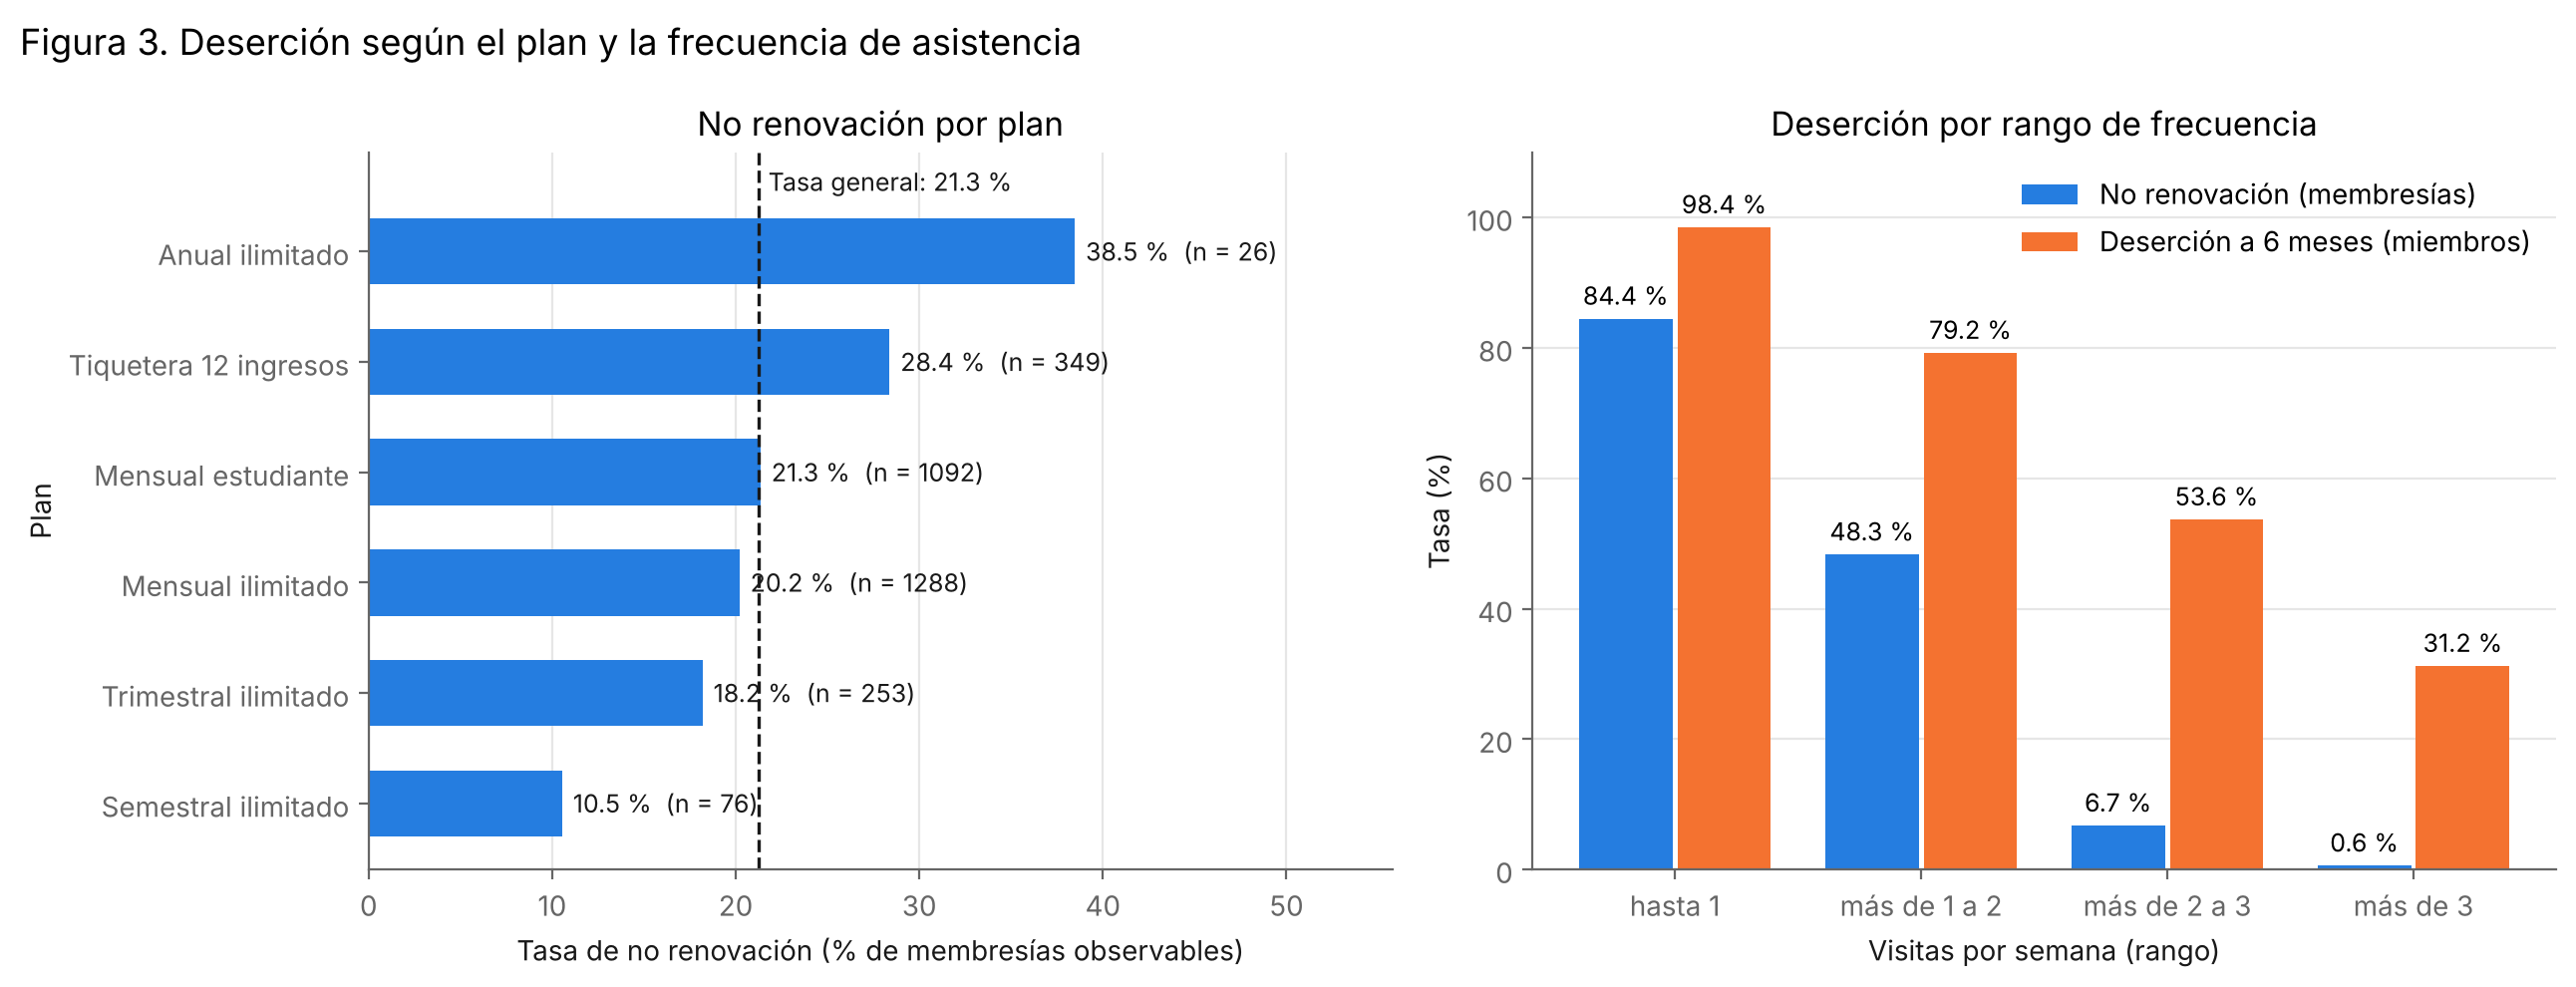

In [15]:
# Figura 3. Tasa de no renovación por plan y deserción por rango de frecuencia
NARANJA = "#f47230"   # segunda serie (deserción a 6 meses)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

# Izquierda: tasa de no renovación por plan, ordenada de menor a mayor (la mayor queda arriba)
planes = plan_detalle.sort_values("tasa_no_renovacion")
ax1.barh(planes.index, planes["tasa_no_renovacion"], color=AZUL, height=0.6)
etiquetas_plan = planes["tasa_no_renovacion"].map("{:.1f} %".format) + "  (n = " + planes["membresias"].astype(str) + ")"
ax1.bar_label(ax1.containers[0], labels=etiquetas_plan, padding=4, color="#191919", fontsize=9)
tasa_general = observables["no_renovo"].mean() * 100
ax1.axvline(tasa_general, color="#191919", linestyle="--", linewidth=1.2)
ax1.text(tasa_general + 0.5, len(planes) - 0.45, f"Tasa general: {tasa_general:.1f} %", color="#191919", fontsize=9)
ax1.set_title("No renovación por plan")
ax1.set_xlabel("Tasa de no renovación (% de membresías observables)")
ax1.set_ylabel("Plan")
ax1.set_xlim(0, planes["tasa_no_renovacion"].max() * 1.45)
ax1.set_ylim(-0.6, len(planes) - 0.1)
ax1.grid(axis="y", visible=False)

# Derecha: barras agrupadas por rango de frecuencia (orden lógico de la categoría)
x = pd.Series(range(len(frecuencia_desercion)), dtype=float)
ancho = 0.38
barras_m = ax2.bar(x - ancho / 2 - 0.01, frecuencia_desercion["tasa_no_renovacion"], width=ancho, color=AZUL,
                   label="No renovación (membresías)")
barras_s = ax2.bar(x + ancho / 2 + 0.01, frecuencia_desercion["tasa_desercion_6m"], width=ancho, color=NARANJA,
                   label="Deserción a 6 meses (miembros)")
ax2.bar_label(barras_m, labels=frecuencia_desercion["tasa_no_renovacion"].map("{:.1f} %".format), padding=3, fontsize=9)
ax2.bar_label(barras_s, labels=frecuencia_desercion["tasa_desercion_6m"].map("{:.1f} %".format), padding=3, fontsize=9)
ax2.set_xticks(x, frecuencia_desercion.index.astype(str))
ax2.set_title("Deserción por rango de frecuencia")
ax2.set_xlabel("Visitas por semana (rango)")
ax2.set_ylabel("Tasa (%)")
ax2.set_ylim(0, 110)
ax2.legend(frameon=False, loc="upper right")
ax2.grid(axis="x", visible=False)

fig.suptitle("Figura 3. Deserción según el plan y la frecuencia de asistencia", fontsize=13, x=0.01, ha="left")
fig.tight_layout()
fig.savefig(RUTA_FIGURAS / "churn_by_plan_and_frequency.png", dpi=150, bbox_inches="tight")
plt.show()


**Interpretación (Figura 3):** a la izquierda, la tiquetera es el plan con más no renovación (28,4 %) entre los planes con suficientes casos. El anual aparece primero (38,5 %), pero con solo 26 membresías su tasa no es estable. A la derecha se ve la relación más fuerte del análisis: las dos tasas bajan de forma escalonada al aumentar la frecuencia. En cada rango, la deserción a 6 meses (naranja) es mayor que la no renovación por membresía (azul), porque basta una membresía no renovada en los primeros seis meses para que el miembro cuente como desertor.

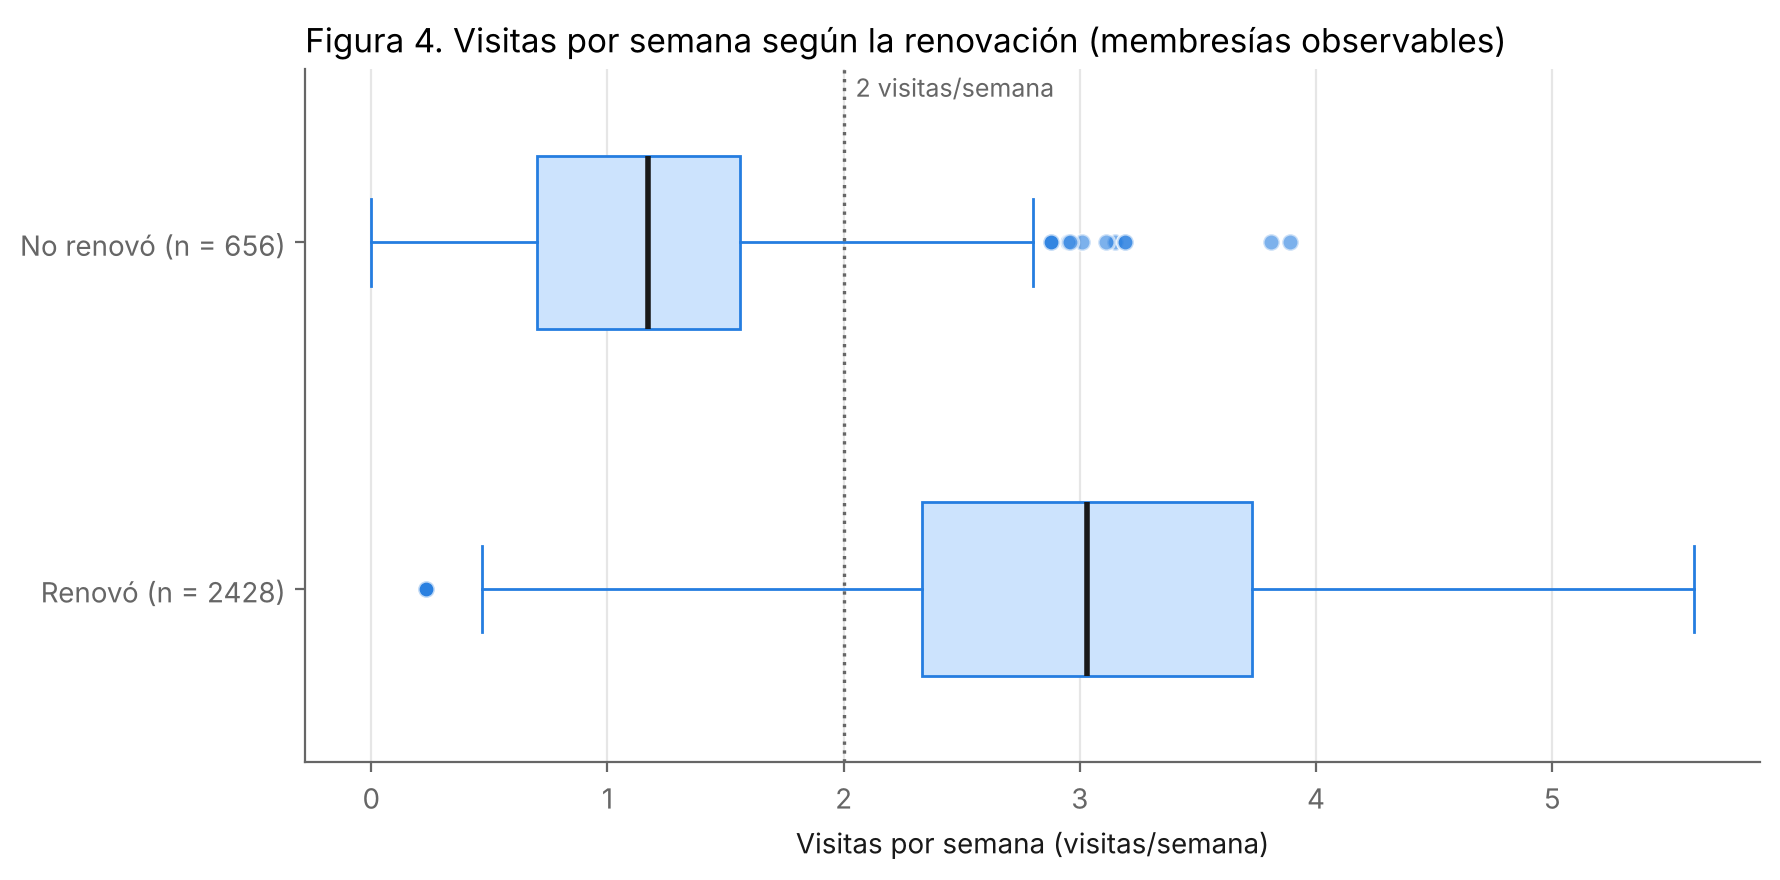

In [16]:
# Figura 4. Visitas por semana según si la membresía se renovó o no
renovo = observables.loc[~observables["no_renovo"], "visitas_semana"]
no_renovo = observables.loc[observables["no_renovo"], "visitas_semana"]

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.boxplot([renovo, no_renovo], tick_labels=[f"Renovó (n = {len(renovo)})", f"No renovó (n = {len(no_renovo)})"],
           orientation="horizontal", widths=0.5, patch_artist=True,
           boxprops={"facecolor": "#cce3fd", "edgecolor": AZUL}, medianprops={"color": "#191919", "linewidth": 2},
           whiskerprops={"color": AZUL}, capprops={"color": AZUL},
           flierprops={"marker": "o", "markersize": 6, "markerfacecolor": AZUL, "markeredgecolor": "white", "alpha": 0.6})
ax.axvline(2, color="#666666", linestyle=":", linewidth=1.2)
ax.text(2.05, 2.42, "2 visitas/semana", color="#666666", fontsize=9)
ax.set_title("Figura 4. Visitas por semana según la renovación (membresías observables)", loc="left")
ax.set_xlabel("Visitas por semana (visitas/semana)")
ax.grid(axis="y", visible=False)
fig.tight_layout()
fig.savefig(RUTA_FIGURAS / "weekly_visits_by_renewal_boxplot.png", dpi=150, bbox_inches="tight")
plt.show()


**Interpretación (Figura 4):** las dos cajas casi no se solapan. El 50 % central de las membresías que no se renovaron está entre 0,70 y 1,56 visitas por semana; el de las renovadas, entre 2,33 y 3,73. La línea de 2 visitas por semana separa casi por completo los dos grupos, así que es un umbral práctico de alerta.

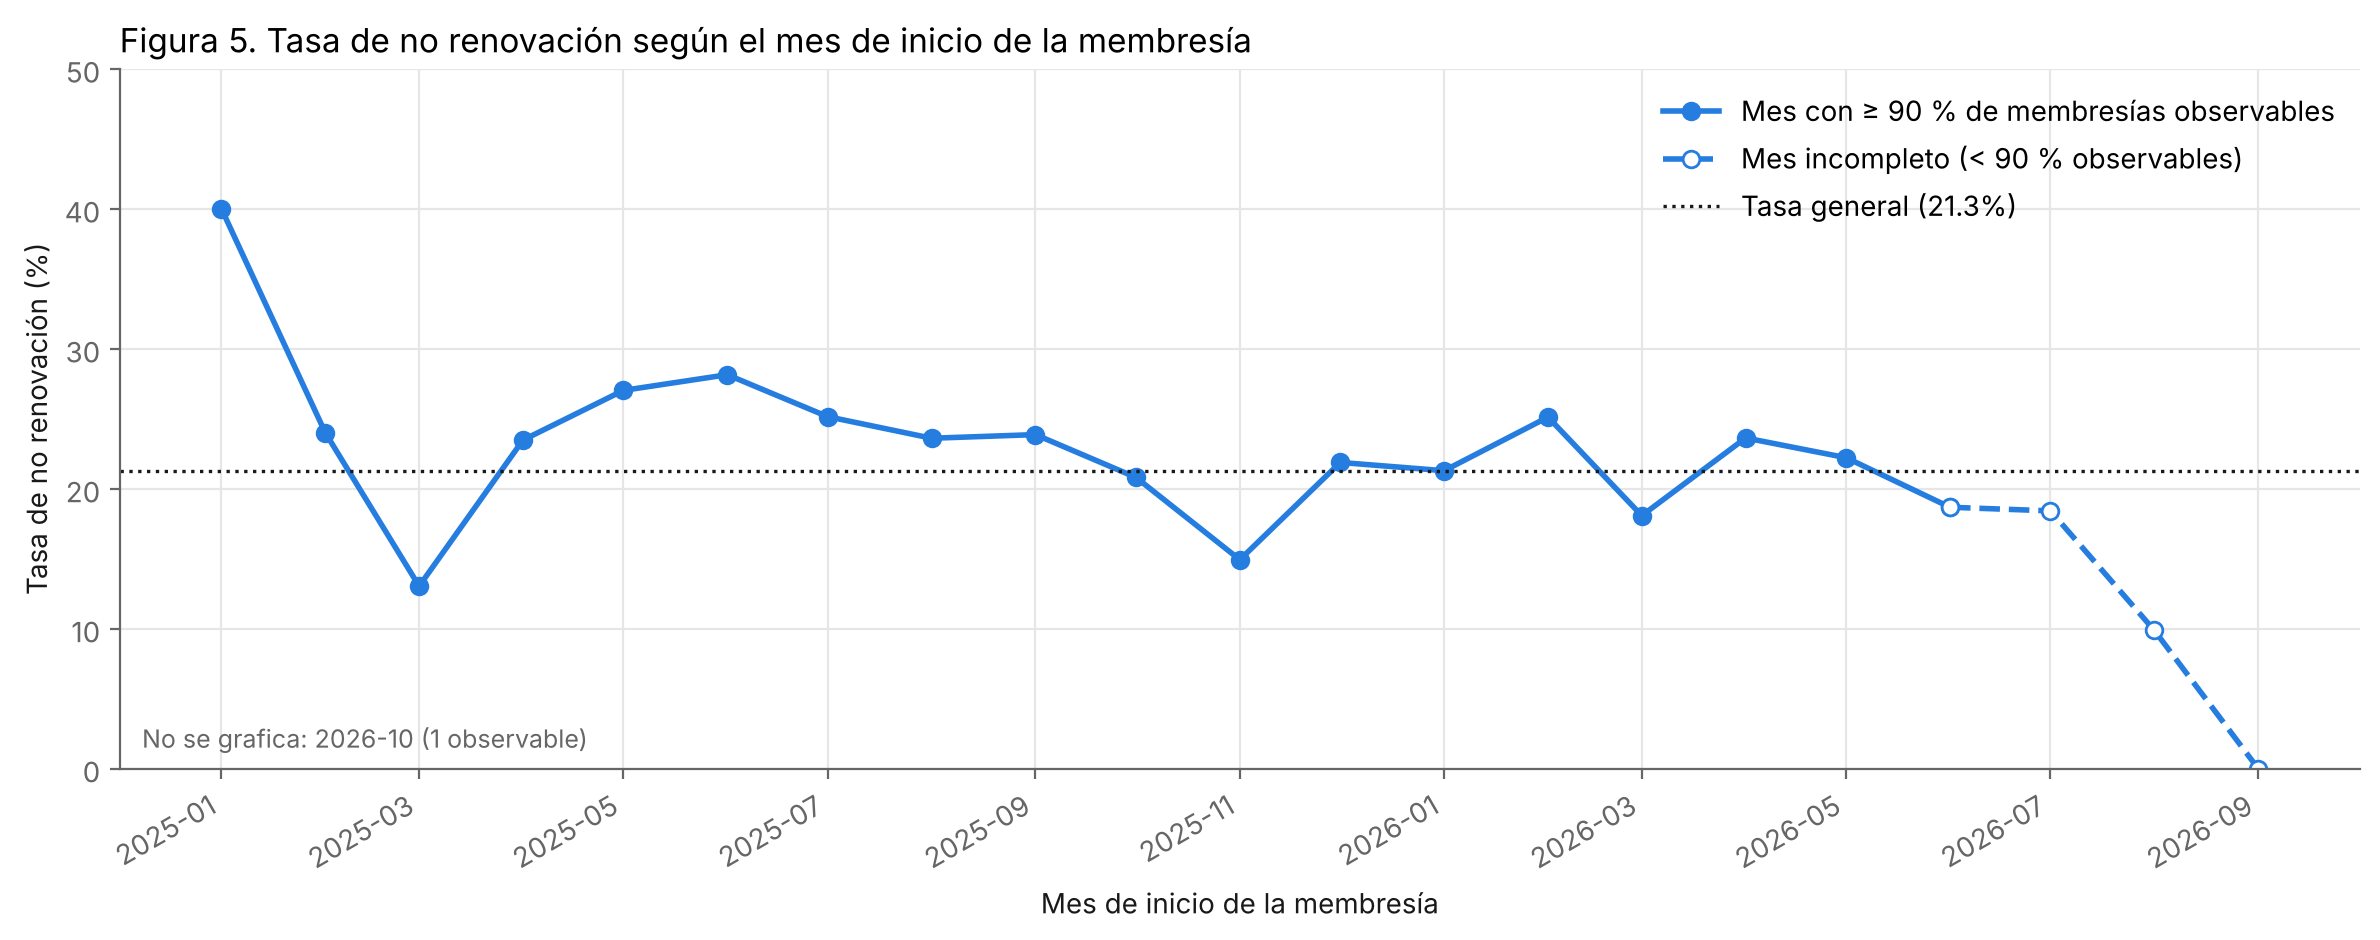

In [17]:
# Figura 5. Tasa mensual de no renovación según el mes de inicio
# Se omiten los meses con menos de 10 membresías observables: su tasa no es representativa
serie = tasa_mensual[tasa_mensual["membresias_observables"] >= 10].copy()
omitidos = tasa_mensual[tasa_mensual["membresias_observables"] < 10]
serie.index = serie.index.to_timestamp()          # Period → fecha, para el eje x
completo = serie["porcentaje_observable"] >= 90   # meses con resultado conocido para al menos el 90 %
ultimo_completo = serie.index[completo].max()

fig, ax = plt.subplots(figsize=(12, 4.8))
# Tramo confiable: línea continua
ax.plot(serie.index[completo], serie.loc[completo, "tasa_no_renovacion"], color=AZUL, linewidth=2,
        marker="o", markersize=6, label="Mes con ≥ 90 % de membresías observables")
# Tramo incompleto (censura al corte): línea punteada desde el último mes completo
incompletos = serie.loc[serie.index >= ultimo_completo]
ax.plot(incompletos.index, incompletos["tasa_no_renovacion"], color=AZUL, linewidth=2, linestyle="--",
        marker="o", markersize=6, markerfacecolor="white", label="Mes incompleto (< 90 % observables)")
ax.axhline(observables["no_renovo"].mean() * 100, color="#191919", linestyle=":", linewidth=1.2,
           label=f"Tasa general ({observables['no_renovo'].mean():.1%})")
ax.set_title("Figura 5. Tasa de no renovación según el mes de inicio de la membresía", loc="left")
ax.set_xlabel("Mes de inicio de la membresía")
ax.set_ylabel("Tasa de no renovación (%)")
ax.set_ylim(0, 50)
if not omitidos.empty:
    texto = "No se grafica: " + ", ".join(omitidos.index.astype(str) + " (" + omitidos["membresias_observables"].astype(str) + " observable)")
    ax.text(0.01, 0.03, texto, transform=ax.transAxes, ha="left", color="#666666", fontsize=9)
ax.legend(frameon=False, loc="upper right")
fig.autofmt_xdate()
fig.tight_layout()
fig.savefig(RUTA_FIGURAS / "monthly_churn_trend.png", dpi=150, bbox_inches="tight")
plt.show()


**Interpretación (Figura 5):** en los meses con resultado conocido la tasa oscila alrededor de la tasa general (21,3 %), sin tendencia sostenida, salvo el pico de enero de 2025 (40 %, primer mes del periodo, con solo miembros nuevos). La caída final (línea punteada) no es una mejora: corresponde a meses cuyas membresías aún no han terminado al corte. Por eso esos meses se marcan como incompletos, y octubre de 2026, con una sola membresía observable, no se grafica.

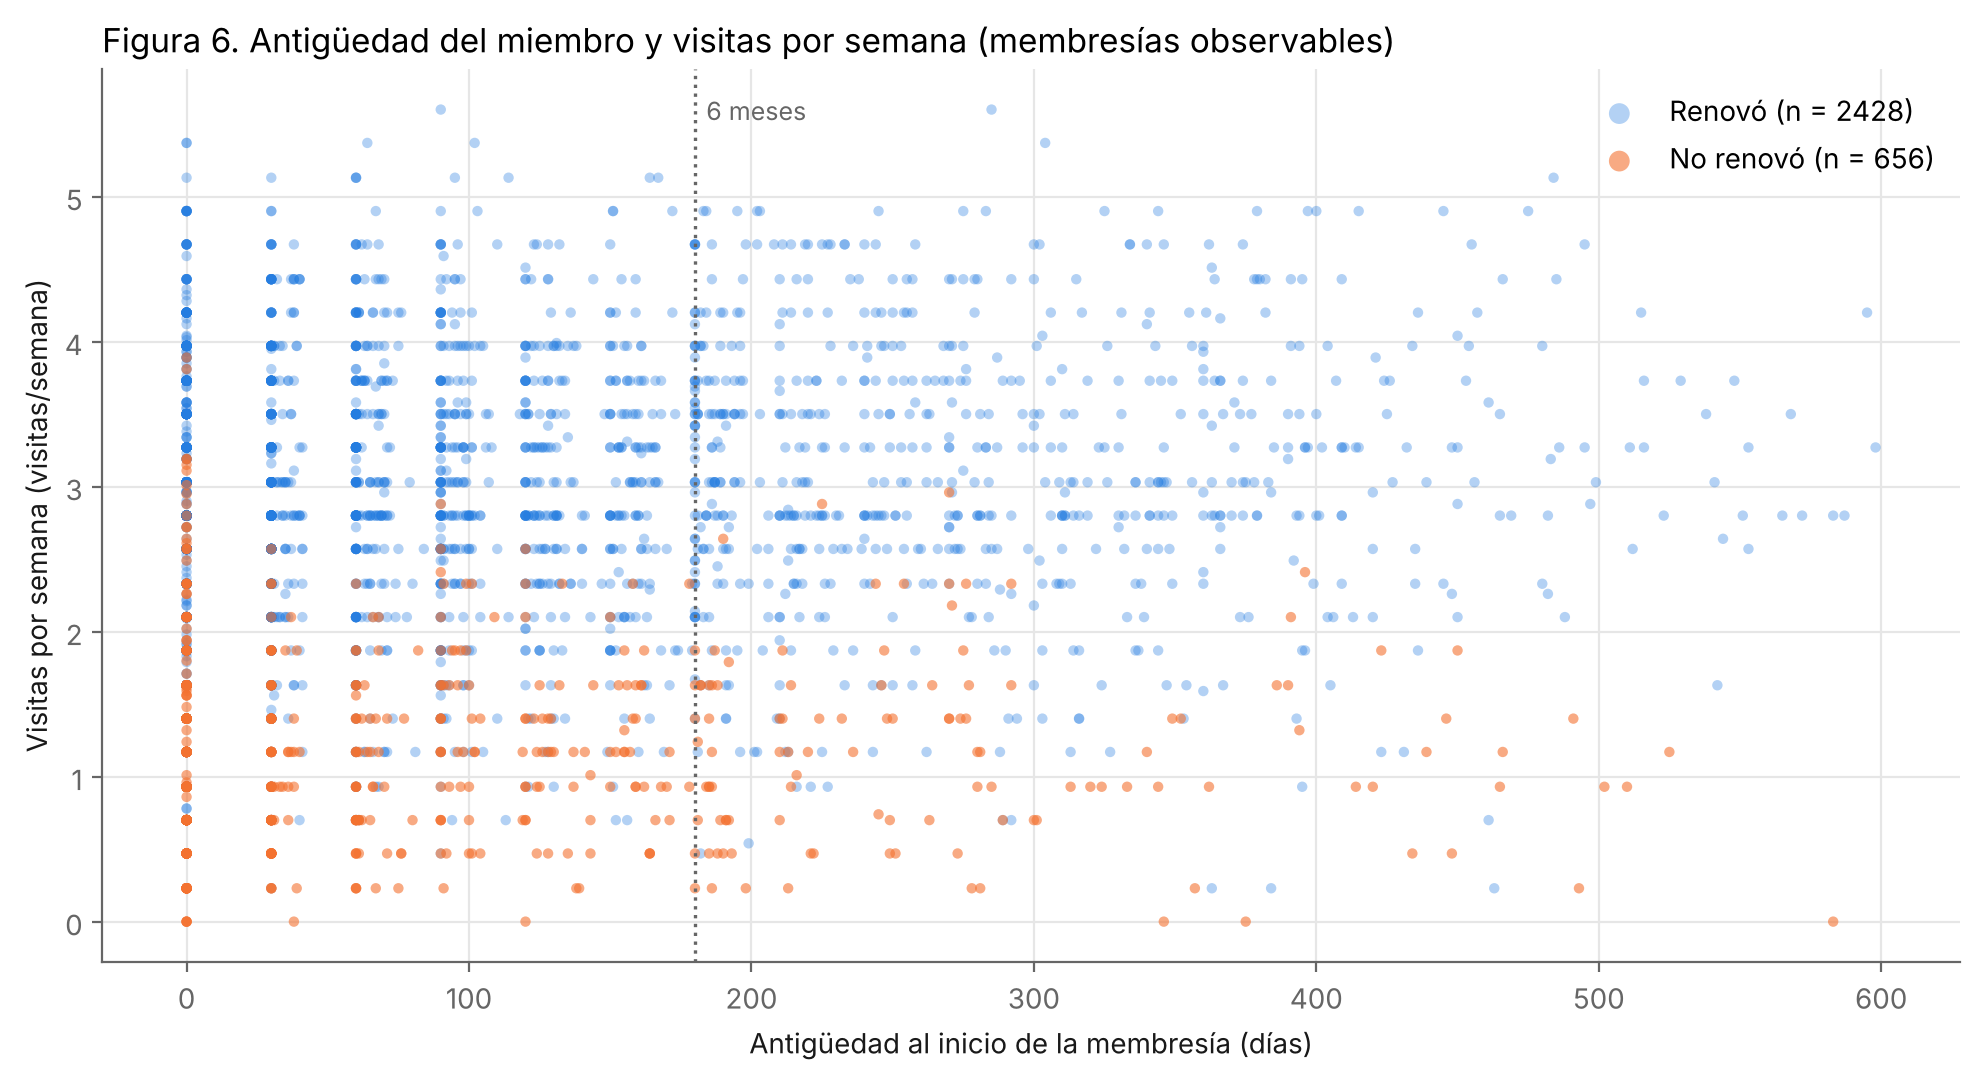

In [18]:
# Figura 6. Antigüedad vs. visitas por semana, según la renovación
fig, ax = plt.subplots(figsize=(10, 5.5))
renovaron = observables[~observables["no_renovo"]]
no_renovaron = observables[observables["no_renovo"]]
# Transparencia para ver la densidad: muchas membresías comparten la misma antigüedad (0, 30, 60… días)
ax.scatter(renovaron["antiguedad_dias"], renovaron["visitas_semana"],
           s=14, color=AZUL, alpha=0.35, edgecolors="none", label=f"Renovó (n = {len(renovaron)})")
ax.scatter(no_renovaron["antiguedad_dias"], no_renovaron["visitas_semana"],
           s=14, color=NARANJA, alpha=0.6, edgecolors="none", label=f"No renovó (n = {len(no_renovaron)})")
ax.axvline(180, color="#666666", linestyle=":", linewidth=1.2)
ax.text(184, 0.97, "6 meses", color="#666666", fontsize=9, transform=ax.get_xaxis_transform(), va="top")
ax.set_title("Figura 6. Antigüedad del miembro y visitas por semana (membresías observables)", loc="left")
ax.set_xlabel("Antigüedad al inicio de la membresía (días)")
ax.set_ylabel("Visitas por semana (visitas/semana)")
ax.legend(frameon=False, loc="upper right", markerscale=2)
fig.tight_layout()
fig.savefig(RUTA_FIGURAS / "visits_vs_tenure_scatter.png", dpi=150, bbox_inches="tight")
plt.show()


**Interpretación (Figura 6):** los puntos naranjas (no renovó) se concentran por debajo de 2 visitas por semana, en cualquier antigüedad; los azules (renovó) dominan por encima de esa línea. La mayoría de los puntos está a la izquierda de la línea de 6 meses, lo que confirma que el negocio depende de miembros nuevos, y la frontera entre renovar o no la marca más la frecuencia que la antigüedad. Esto concuerda con las correlaciones de la sección 5.4 (−0,64 para visitas y −0,14 para antigüedad).

# 6. Hallazgos, respuesta a la pregunta y recomendaciones (Momento 6)

*Se desarrolla en un avance posterior.*